# 01. Разведка данных и постановка AIOps-задачи

Этот notebook фиксирует постановку задачи и проверяет, можно ли вообще строить на этих данных контур раннего предупреждения. Здесь еще рано выбирать финальную архитектуру: сначала нужно доказать, что данные не сводятся к простой классификации CSV, а действительно описывают оконную AIOps-ситуацию с workload, логами, KPI и временным приближением события.

Формальная постановка такая: по окну наблюдения нужно предсказать приближение деградации или сбоя. На входе находятся KPI-метрики, логовые признаки, признаки доступности модальностей и workload/context. На выходе остаются несколько разных задач: `y_warning`, `y_anomaly`, `y_risk` и early-warning горизонты `horizon_30s`, `horizon_60s`, `horizon_120s`, `horizon_300s`.

Ограничение протокола важно зафиксировать сразу. `train`, `validation` и `test` не смешиваются; thresholds выбираются только по `validation`; `test` используется только для финального отчета. Поэтому `01` не выбирает модель и не подбирает пороги. Он формирует проверяемые требования, которые затем должны пройти через `02_baseline_pipeline.ipynb`.


## 1. Strict data contract как вход исследования

Загружаем strict contract и настраиваем единый стиль графиков. Contract здесь не просто технический CSV: это единая точка входа для следующих notebook, где raw logs и KPI уже приведены к окнам наблюдения, target и split.

| Группа полей | Примеры | Зачем нужна |
|---|---|---|
| Identity | `run_id`, `workload`, `scenario`, `split`, `window_ts` | контроль разбиения, времени и домена |
| Modalities | `log_available`, `kpi_available`, `has_both_modalities` | проверка полноты источников и устойчивости fused-подхода |
| KPI features | CPU, memory, disk, network, `*_mean`, `*_delta`, `*_slope` | числовая динамика окна и отклонения метрик |
| Log features | `log_text`, counts/rates, component statistics | событийная и текстовая динамика перед деградацией |
| Targets | `y_warning`, `y_anomaly`, `y_risk`, `horizon_60s` | отдельные задачи warning, risk и early-warning горизонтов |

Strict contract является единой точкой входа для `02` и `03`. Все модели обучаются и сравниваются только через него, иначе сравнение baseline и Efficient HADES перестает быть честным.


In [1]:
from __future__ import annotations

import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="deep",
    rc={
        "figure.figsize": (11, 5),
        "axes.titlesize": 13,
        "axes.labelsize": 11,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.frameon": True,
    },
)
pd.options.display.max_columns = 80
pd.options.display.width = 160

PROJECT_ROOT = Path.cwd()
RAW_DATA = PROJECT_ROOT / "raw_data"
CONTRACT_PATH = PROJECT_ROOT / "dashboard" / "artifacts" / "contract" / "strict_intensity_contract.csv.gz"

SPLIT_ORDER = ["train", "validation", "test"]
TARGET_ORDER = ["y_warning", "y_anomaly", "y_risk", "horizon_30s", "horizon_60s", "horizon_120s", "horizon_300s"]
TARGET_LABELS = {
    "y_warning": "Предупреждение",
    "y_anomaly": "Аномалия",
    "y_risk": "Риск",
    "horizon_30s": "30 сек",
    "horizon_60s": "60 сек",
    "horizon_120s": "120 сек",
    "horizon_300s": "300 сек",
}


def run_command(cmd: list[str]) -> None:
    print(">", " ".join(cmd))
    subprocess.run(cmd, check=True, cwd=str(PROJECT_ROOT))


def load_contract() -> pd.DataFrame:
    if not CONTRACT_PATH.exists():
        run_command([sys.executable, "-m", "dashboard.pipeline.build_contract", "--raw-data", "raw_data"])
    df = pd.read_csv(CONTRACT_PATH, low_memory=False)
    for col in ["window_ts", "window_end", "run_start", "run_end", "fail_start"]:
        if col in df.columns:
            df[col] = pd.to_datetime(df[col], errors="coerce")
    return df


def label_target(name: str) -> str:
    return TARGET_LABELS.get(name, name)


def short_kpi_name(name: str, max_len: int = 46) -> str:
    clean = (
        name.replace("kpi_", "")
        .replace("__mean_dim__", "__")
        .replace("__", " / ")
        .replace("_", " ")
    )
    return clean if len(clean) <= max_len else clean[: max_len - 1] + "..."


contract = load_contract()
print(f"Strict contract: {contract.shape[0]} окон, {contract.shape[1]} столбцов")
print(f"Workload: {contract['workload'].nunique()} | run_id: {contract['run_id'].nunique()}")


Strict contract: 2883 окон, 1132 столбцов
Workload: 16 | run_id: 228


## 2. Что лежит в исходных данных

Сначала полезно посмотреть не на метрики модели, а на сам источник. Нас интересует, насколько равномерно представлены workload, есть ли в данных разные сценарии и достаточно ли окон для последующего split.

In [2]:
raw_rows = []
if RAW_DATA.exists():
    for workload_dir in sorted([p for p in RAW_DATA.iterdir() if p.is_dir()]):
        log_files = list(workload_dir.rglob("*.log"))
        csv_files = list(workload_dir.rglob("*.csv"))
        kpi_files = [
            p
            for p in csv_files
            if ("kpi" in p.name.lower()) or ("metric" in p.name.lower())
        ]
        raw_rows.append(
            {
                "workload": workload_dir.name,
                "log_files": len(log_files),
                "kpi_csv_files": len(kpi_files),
                "csv_files_total": len(csv_files),
                "files_total": sum(1 for p in workload_dir.rglob("*") if p.is_file()),
            }
        )

raw_summary = pd.DataFrame(raw_rows).sort_values("workload").reset_index(drop=True)
contract_overview = pd.DataFrame(
    [
        {"Показатель": "Окон в contract", "Значение": f"{len(contract):,}".replace(",", " ")},
        {"Показатель": "Уникальных запусков", "Значение": contract["run_id"].nunique()},
        {"Показатель": "Workload", "Значение": contract["workload"].nunique()},
        {"Показатель": "Split", "Значение": ", ".join(contract["split"].dropna().unique())},
        {"Показатель": "Доля окон с логами", "Значение": f"{contract['log_available'].mean() * 100:.1f}%" if "log_available" in contract else "n/a"},
        {"Показатель": "Доля окон с KPI", "Значение": f"{contract['kpi_available'].mean() * 100:.1f}%" if "kpi_available" in contract else "n/a"},
    ]
)

display(contract_overview)
display(raw_summary)


,Показатель,Значение
0,Окон в contract,2 883
1,Уникальных запусков,228
2,Workload,16
3,Split,"test, train, validation"
4,Доля окон с логами,57.4%
5,Доля окон с KPI,97.1%


,workload,log_files,kpi_csv_files,csv_files_total,files_total
0,.ipynb_checkpoints,0,0,0,0
1,aggregation,35,0,6,1147
2,als,33,0,3,1028
3,bayes,33,0,3,1024
4,graph_pagerank,30,0,3,1135
5,join,30,0,3,1135
6,lda,31,0,3,1022
7,nweight,23,0,2,1127
8,repartition,35,0,3,1102
9,rf,30,0,3,1135


По этой таблице видно, что дальше мы работаем не с одним ровным источником, а с набором разных workload и окон. Это важное стартовое наблюдение: EDA должен проверять не только классы, но и доменную структуру данных.

Пока отсюда не следует готовое решение. Следует только вопрос для следующих шагов: одинаково ли представлены workload в split и не будет ли модель путать особенности домена с признаками проблемного состояния.


## 3. Split/workload integrity

Теперь смотрим на покрытие workload в `train`, `validation` и `test`. Этот график нужен не для красоты: он показывает, насколько честным может быть дальнейшее сравнение моделей и где возможен domain bias.

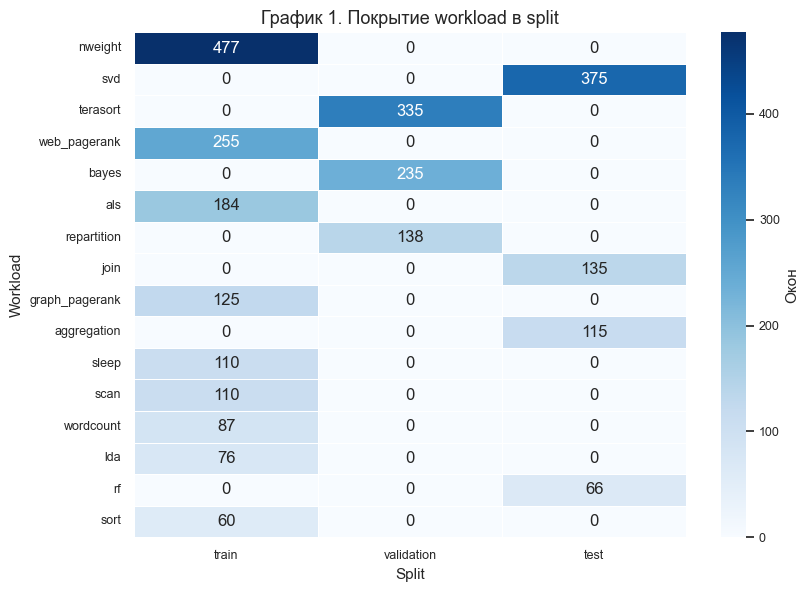

In [3]:
split_workload = (
    contract.groupby(["workload", "split"])
    .size()
    .reset_index(name="windows")
)
workload_order = (
    split_workload.groupby("workload")["windows"]
    .sum()
    .sort_values(ascending=False)
    .index
)
split_cols = [s for s in SPLIT_ORDER if s in contract["split"].unique()]
coverage = (
    split_workload.pivot(index="workload", columns="split", values="windows")
    .reindex(index=workload_order, columns=split_cols)
    .fillna(0)
    .astype(int)
)

plt.figure(figsize=(8.5, max(5, 0.38 * len(coverage))))
sns.heatmap(
    coverage,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.45,
    linecolor="white",
    cbar_kws={"label": "Окон"},
)
plt.title("График 1. Покрытие workload в split")
plt.xlabel("Split")
plt.ylabel("Workload")
plt.tight_layout()
plt.show()


График читается как карта того, где у нас есть опора для обучения и проверки. Он не говорит, какая модель будет лучше, но показывает, где могут появиться искажения оценки.

В `02` это место должно превратиться в проверку: baseline надо будет смотреть не только в среднем по test, но и по workload. Если среднее качество нормальное, а на отдельных workload модель разваливается, такой baseline нельзя считать надежной точкой отсчета.


## 4. Modality availability

Идеальная fused-модель предполагает, что у нас есть обе модальности: логи и метрики. В реальных данных это почти никогда не гарантировано. Поэтому перед обучением нужно понять, насколько часто окно содержит только часть источников.

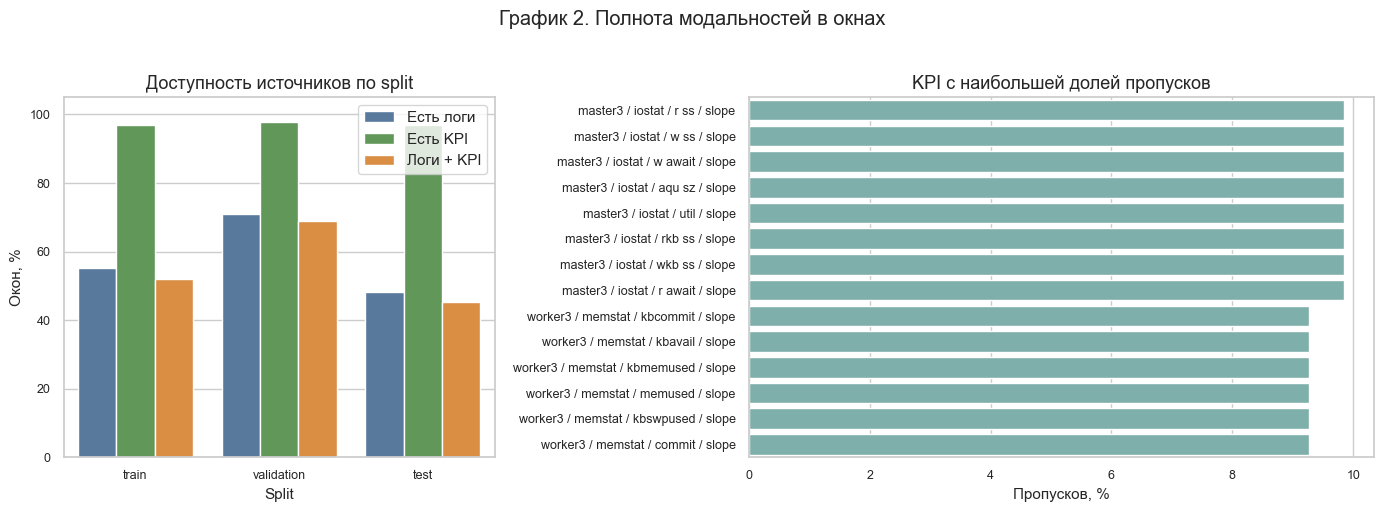

In [4]:
availability_cols = [c for c in ["log_available", "kpi_available", "has_both_modalities"] if c in contract.columns]
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.0, 1.45]})

if availability_cols:
    availability = (
        contract.groupby("split")[availability_cols]
        .mean()
        .reindex(split_cols)
        .reset_index()
        .melt(id_vars="split", var_name="source", value_name="share")
    )
    source_labels = {
        "log_available": "Есть логи",
        "kpi_available": "Есть KPI",
        "has_both_modalities": "Логи + KPI",
    }
    availability["source"] = availability["source"].map(source_labels)
    availability["share_pct"] = availability["share"] * 100.0

    sns.barplot(
        data=availability,
        x="split",
        y="share_pct",
        hue="source",
        palette=["#4C78A8", "#59A14F", "#F28E2B"],
        ax=axes[0],
    )
    axes[0].set_title("Доступность источников по split")
    axes[0].set_xlabel("Split")
    axes[0].set_ylabel("Окон, %")
    axes[0].set_ylim(0, 105)
    axes[0].legend(title="")
else:
    axes[0].text(0.5, 0.5, "Нет колонок доступности", ha="center", va="center")
    axes[0].axis("off")

kpi_cols = [c for c in contract.columns if c.startswith("kpi_") and "__" in c]
if kpi_cols:
    missing = (
        contract[kpi_cols]
        .isna()
        .mean()
        .sort_values(ascending=False)
        .head(14)
        .rename("missing_share")
        .reset_index()
        .rename(columns={"index": "kpi_feature"})
    )
    missing["missing_pct"] = missing["missing_share"] * 100.0
    missing["feature"] = missing["kpi_feature"].map(short_kpi_name)
    sns.barplot(data=missing, y="feature", x="missing_pct", color="#76B7B2", ax=axes[1])
    axes[1].set_title("KPI с наибольшей долей пропусков")
    axes[1].set_xlabel("Пропусков, %")
    axes[1].set_ylabel("")
else:
    axes[1].text(0.5, 0.5, "KPI-колонки не найдены", ha="center", va="center")
    axes[1].axis("off")

fig.suptitle("График 2. Полнота модальностей в окнах", y=1.02)
plt.tight_layout()
plt.show()


Здесь видно, насколько fused-постановка зависит от качества данных. Если окно содержит только часть источников, модель все равно может выдать score, но доверие к такому score уже другое.

Для `02` это формирует проверку: baseline должен показать, насколько информативны логи отдельно, KPI отдельно и их объединение. Пока мы не знаем, какая модальность окажется сильнее, и именно поэтому EDA не должен заранее назначать победителя.


## 5. Target distribution

Следующий вопрос - что именно мы пытаемся предсказывать. `warning`, `risk`, `anomaly` и горизонты раннего предупреждения имеют разный смысл. Оценивать их одной общей цифрой нельзя.

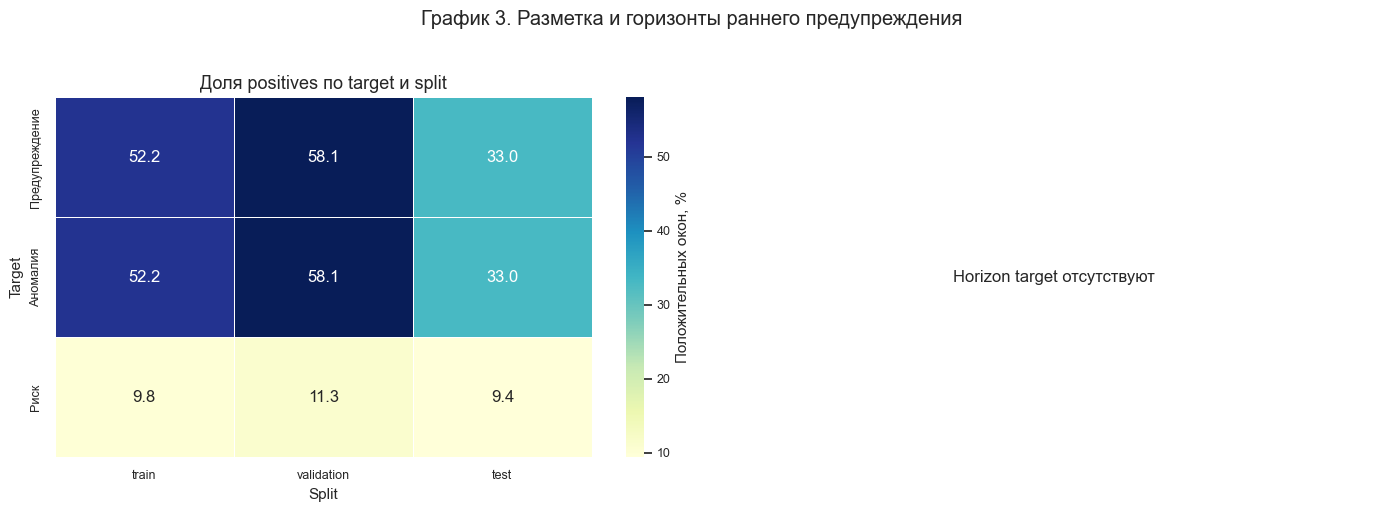

In [5]:
target_cols = [c for c in TARGET_ORDER if c in contract.columns]
target_split = (
    contract.groupby("split")[target_cols]
    .mean()
    .reindex(split_cols)
    .T
)
target_split.index = [label_target(c) for c in target_split.index]

horizon_cols = [c for c in ["horizon_30s", "horizon_60s", "horizon_120s", "horizon_300s"] if c in contract.columns]
horizon_long = (
    contract.groupby("split")[horizon_cols]
    .mean()
    .reindex(split_cols)
    .reset_index()
    .melt(id_vars="split", var_name="target", value_name="share")
)
horizon_long["seconds"] = horizon_long["target"].str.extract(r"(\d+)").astype(int)
horizon_long["share_pct"] = horizon_long["share"] * 100.0

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.05, 1.0]})

sns.heatmap(
    target_split * 100.0,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.45,
    linecolor="white",
    cbar_kws={"label": "Положительных окон, %"},
    ax=axes[0],
)
axes[0].set_title("Доля positives по target и split")
axes[0].set_xlabel("Split")
axes[0].set_ylabel("Target")

if not horizon_long.empty:
    sns.lineplot(
        data=horizon_long,
        x="seconds",
        y="share_pct",
        hue="split",
        marker="o",
        linewidth=2.2,
        ax=axes[1],
    )
    axes[1].set_title("Как меняется доля positives по горизонту")
    axes[1].set_xlabel("Горизонт, сек")
    axes[1].set_ylabel("Положительных окон, %")
    axes[1].set_xticks(sorted(horizon_long["seconds"].unique()))
    axes[1].legend(title="Split")
else:
    axes[1].text(0.5, 0.5, "Horizon target отсутствуют", ha="center", va="center")
    axes[1].axis("off")

fig.suptitle("График 3. Разметка и горизонты раннего предупреждения", y=1.02)
plt.tight_layout()
plt.show()


Этот график сразу показывает, почему нельзя оценивать систему одной общей метрикой. Горизонты и базовые метки имеют разную плотность positives, а значит, будут по-разному реагировать на порог.

Пока мы не выбираем основной target. Мы только фиксируем, что в `02` baseline должен считать метрики отдельно по нескольким target. Иначе можно получить красивый результат на одной постановке и не заметить, что другая, более ранняя, почти не отделима.


## 6. Workload/target dependency

Теперь проверяем, не связано ли появление positives слишком сильно с workload. Это не означает ошибку в данных: разные workload действительно могут иметь разный профиль деградации. Но для модели это риск shortcut-поведения.

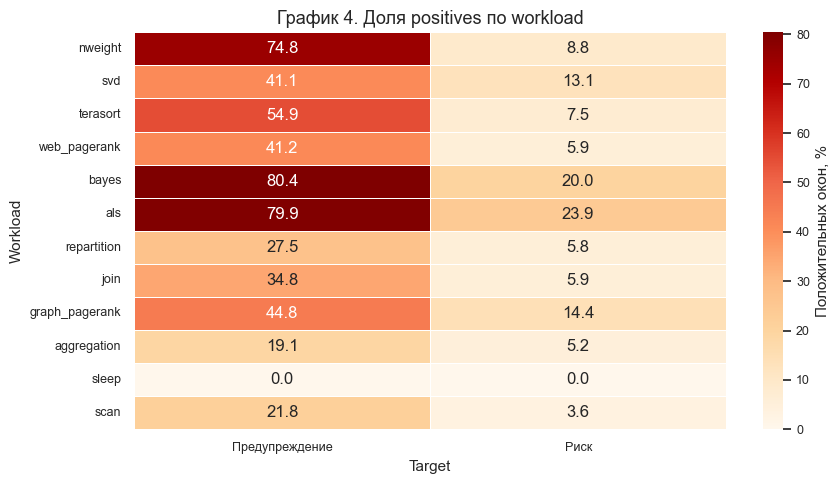

In [6]:
workload_targets = [c for c in ["y_warning", "y_risk", "horizon_60s", "horizon_120s", "horizon_300s"] if c in contract.columns]
top_workloads = contract["workload"].value_counts().head(12).index
workload_target = (
    contract[contract["workload"].isin(top_workloads)]
    .groupby("workload")[workload_targets]
    .mean()
    .reindex(top_workloads)
)
workload_target.columns = [label_target(c) for c in workload_target.columns]

plt.figure(figsize=(9, max(5, 0.38 * len(workload_target))))
sns.heatmap(
    workload_target * 100.0,
    annot=True,
    fmt=".1f",
    cmap="OrRd",
    linewidths=0.45,
    linecolor="white",
    cbar_kws={"label": "Положительных окон, %"},
)
plt.title("График 4. Доля positives по workload")
plt.xlabel("Target")
plt.ylabel("Workload")
plt.tight_layout()
plt.show()


На этом графике хорошо видно, почему средняя метрика может быть обманчивой. Если часть workload содержит больше warning-окон, то модель может получить неплохой score просто за счет узнавания домена.

Для следующего notebook отсюда появляется не готовый ответ, а проверяемый вопрос: как baseline ведет себя по workload и сохраняется ли качество, если смотреть не только общий test, а отдельные домены.


## 7. KPI domain shift

Target-rate - это только половина истории. Вторая половина - сами KPI. Если нормальный уровень CPU, Disk или Network отличается между workload, preprocessing должен быть достаточно осторожным.

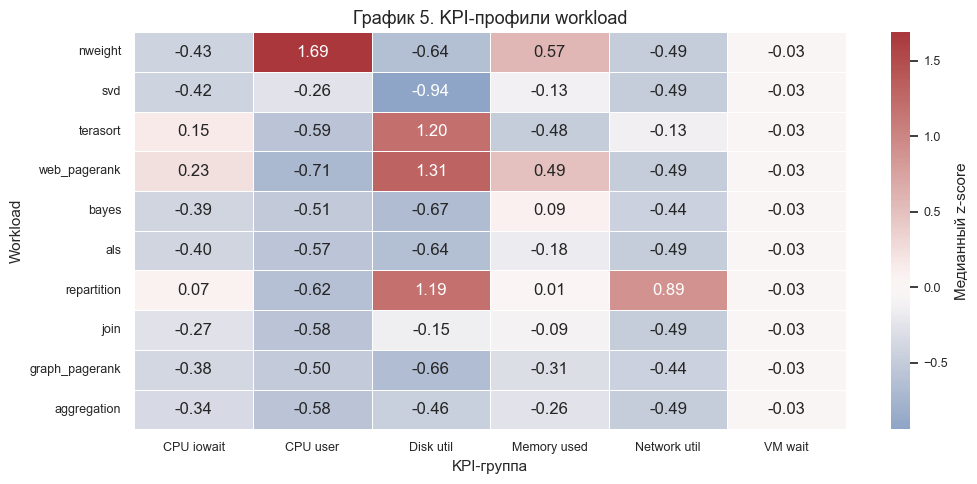

In [7]:
metric_tokens = {
    "cpustat__user__mean_dim__mean": "CPU user",
    "cpustat__iowait__mean_dim__mean": "CPU iowait",
    "iostat__util__mean_dim__mean": "Disk util",
    "memstat__memused__mean_dim__mean": "Memory used",
    "netstat__ifutil__mean_dim__mean": "Network util",
    "vmstat__wa__mean_dim__mean": "VM wait",
}

selected_metrics = {}
for token, label in metric_tokens.items():
    col = next((c for c in contract.columns if c.startswith("kpi_") and token in c), None)
    if col:
        selected_metrics[label] = col

if selected_metrics:
    drift_workloads = contract["workload"].value_counts().head(10).index
    drift = contract.loc[contract["workload"].isin(drift_workloads), ["workload", *selected_metrics.values()]].copy()
    drift = drift.rename(columns={v: k for k, v in selected_metrics.items()})
    long_drift = drift.melt(id_vars="workload", var_name="metric", value_name="value").dropna()
    long_drift["z"] = long_drift.groupby("metric")["value"].transform(
        lambda s: (s - s.mean()) / (s.std(ddof=0) + 1e-6)
    )
    drift_heat = (
        long_drift.groupby(["workload", "metric"])["z"]
        .median()
        .unstack("metric")
        .reindex(drift_workloads)
    )

    plt.figure(figsize=(10.5, max(5, 0.38 * len(drift_heat))))
    sns.heatmap(
        drift_heat,
        cmap="vlag",
        center=0,
        annot=True,
        fmt=".2f",
        linewidths=0.45,
        linecolor="white",
        cbar_kws={"label": "Медианный z-score"},
    )
    plt.title("График 5. KPI-профили workload")
    plt.xlabel("KPI-группа")
    plt.ylabel("Workload")
    plt.tight_layout()
    plt.show()
else:
    print("Подходящие KPI-колонки не найдены.")


Здесь видно, похожи ли workload друг на друга по базовым метрикам. Если различия заметные, это еще не доказывает, что нужна конкретная нормализация. Но это показывает, что в `02` надо будет сравнить варианты preprocessing, а не брать первый удобный масштаб.

Хороший EDA на этом месте не должен делать вид, что решение уже принято. Он должен честно поставить вопрос: насколько качество baseline зависит от способа нормализации и сохраняется ли сигнал после учета workload.


## 8. Pre-event dynamics

Последний крупный вопрос EDA: есть ли в данных хоть какой-то сигнал до события. Если признаки начинают меняться только после факта, то это не early-warning, а постфактум-детектор.

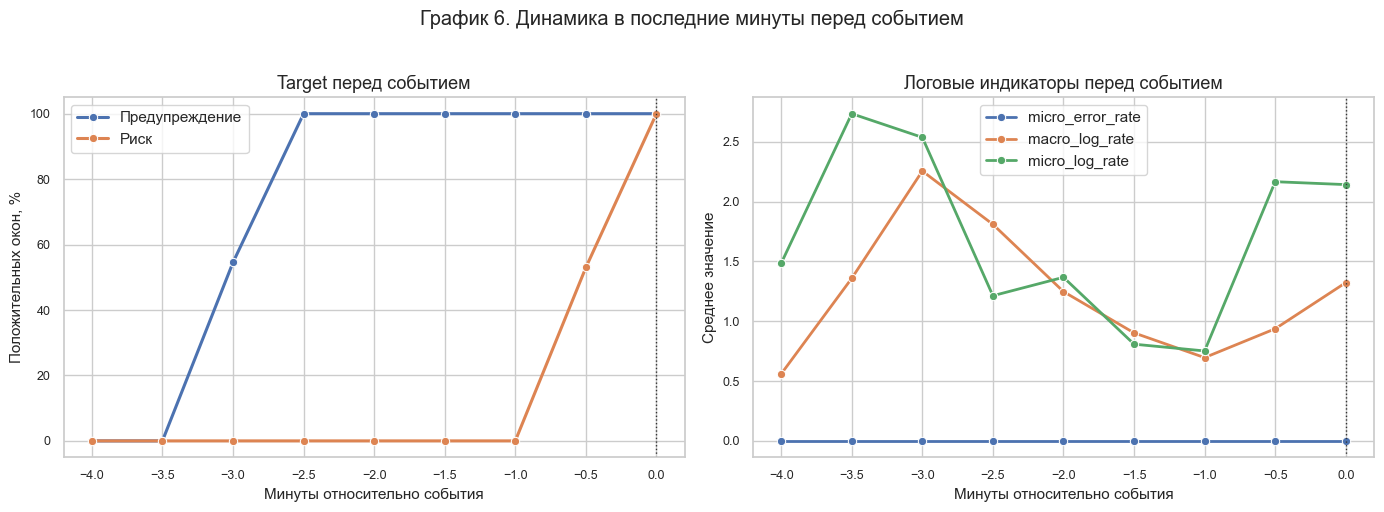

In [8]:
if "minutes_before_fail" not in contract.columns:
    print("Колонка minutes_before_fail отсутствует.")
else:
    pre = contract[contract["minutes_before_fail"].notna()].copy()
    pre = pre[(pre["minutes_before_fail"] >= 0) & (pre["minutes_before_fail"] <= 4.5)]
    pre["minutes_to_event"] = -pre["minutes_before_fail"]
    pre["time_bin"] = (pre["minutes_to_event"] * 2).round() / 2

    agg = {"windows": pre.groupby("time_bin").size()}
    for col in ["y_warning", "y_risk", "micro_error_rate", "macro_log_rate", "micro_log_rate"]:
        if col in pre.columns:
            agg[col] = pre.groupby("time_bin")[col].mean()
    temporal = pd.DataFrame(agg).reset_index().sort_values("time_bin")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    target_cols = [c for c in ["y_warning", "y_risk"] if c in temporal.columns]
    if target_cols:
        target_long = temporal.melt(id_vars="time_bin", value_vars=target_cols, var_name="target", value_name="rate")
        target_long["target"] = target_long["target"].map(label_target)
        target_long["rate_pct"] = target_long["rate"] * 100.0
        sns.lineplot(
            data=target_long,
            x="time_bin",
            y="rate_pct",
            hue="target",
            marker="o",
            linewidth=2.2,
            ax=axes[0],
        )
        axes[0].set_ylabel("Положительных окон, %")
        axes[0].legend(title="")
    else:
        sns.lineplot(data=temporal, x="time_bin", y="windows", marker="o", ax=axes[0])
        axes[0].set_ylabel("Количество окон")

    axes[0].set_title("Target перед событием")
    axes[0].set_xlabel("Минуты относительно события")
    axes[0].axvline(0, color="#333333", linestyle=":", linewidth=1)

    service_cols = [c for c in ["micro_error_rate", "macro_log_rate", "micro_log_rate"] if c in temporal.columns]
    if service_cols:
        service_long = temporal.melt(id_vars="time_bin", value_vars=service_cols, var_name="feature", value_name="value")
        sns.lineplot(
            data=service_long,
            x="time_bin",
            y="value",
            hue="feature",
            marker="o",
            linewidth=2.0,
            ax=axes[1],
        )
        axes[1].legend(title="")
        axes[1].set_ylabel("Среднее значение")
    else:
        sns.lineplot(data=temporal, x="time_bin", y="windows", marker="o", ax=axes[1])
        axes[1].set_ylabel("Количество окон")

    axes[1].set_title("Логовые индикаторы перед событием")
    axes[1].set_xlabel("Минуты относительно события")
    axes[1].axvline(0, color="#333333", linestyle=":", linewidth=1)

    fig.suptitle("График 6. Динамика в последние минуты перед событием", y=1.02)
    plt.tight_layout()
    plt.show()


Этот график нужен как sanity check всей постановки. Если перед событием видна динамика, то задача раннего предупреждения не выглядит искусственной. Если динамика слабая или шумная, это тоже важный результат: значит, в `02` и `03` нельзя будет ждать идеального разделения.

Важно, что здесь мы не доказываем качество модели. Мы только проверяем, что в данных есть временной контекст, ради которого вообще имеет смысл строить оконный pipeline.


## EDA decisions for 02

После `01` у нас нет финальной модели и нет окончательного preprocessing. Зато есть исследовательский контракт: какие target оценивать, какие split считать честными, какие baseline обязаны быть и какие риски надо проверить в `02`.

| Вывод из 01 | Обязательное действие в 02 |
|---|---|
| Workload неоднородны | считать метрики по workload, а не только средний test-score |
| Модальности неполные | обучить и сравнить `availability_only`, logs-only, KPI-only и fused baseline |
| Targets разной плотности | оценивать каждый target отдельно, без одной общей метрики качества |
| Early horizons шумные | не ждать идеального F1 на 30/60s и смотреть FP/FN отдельно |
| KPI-профили отличаются | проверить preprocessing / normalization и не доверять shortcut по workload |
| Есть предсобытийная динамика | оценивать не только window-F1, но и alert-смысл будущей системы |

Этот контракт переводит EDA из набора графиков в список проверок для baseline-пайплайна.


## Итог 01

Этот EDA показывает, что данные подходят для постановки раннего предупреждения, но задача не является простой табличной классификацией. В данных есть доменная неоднородность, неполные модальности, разные по смыслу target и шумная предсобытийная динамика.

`01` не выбирает модель. `01` формирует проверяемые требования к pipeline: честный split, отдельная оценка target, workload breakdown, диагностика модальностей и осторожное отношение к ранним горизонтам. Именно это должен доказать `02_baseline_pipeline.ipynb` перед переходом к Efficient HADES.
